# Facial Expression Recognition (FER) - 2D CNN with Squeeze-and-Excitation (SEResNet2D)
**Architecture:** 2D Residual Convolutional Neural Network with SE Attention (`SEResNet2D`)
**Key Features:**
- Custom ResNet2D with Squeeze-and-Excitation (SE) channel-wise attention
- Test-Time Augmentation (TTA) averaging original & horizontal flipped predictions
- Mixed Precision Training (`torch.amp`) with Gradient Clipping
- Class-weighted Cross-Entropy Loss with label smoothing
- Learning rate scheduling & early stopping evaluated on Validation Macro-F1 score

In [1]:
%%writefile config.yaml
project_name: "Facial_Expression_Recognition_2DCNN"
seed: 42
device: "cuda" # Automatically falls back to 'cpu' or 'mps' in code if unavailable

dataset:
  name: "FER2013"          # Options: "FER2013" or "CK+"
  root_dir: "./data"       # Path containing 'train' and 'val' folders (ImageFolder format)
  img_size: 48             # Standard 48x48 resolution for FER2013 & resized CK+
  in_channels: 1           # 1 for Grayscale, 3 for RGB
  num_classes: 7           # 7 for FER2013 (Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral)
  num_workers: 4
  pin_memory: true
  use_class_weights: true  # Crucial for handling Disgust/Fear minority classes in FER2013/CK+

model:
  architecture: "SEResNet2D"
  base_filters: 64
  dropout_rate: 0.4

training:
  batch_size: 64           # Use 64/128 for FER2013; reduce to 16/32 for CK+
  epochs: 60
  learning_rate: 0.001
  weight_decay: 0.0001
  label_smoothing: 0.1     # Prevents overconfidence on noisy FER2013 labels
  grad_clip_norm: 1.0
  early_stopping_patience: 10
  checkpoint_dir: "./checkpoints"

scheduler:
  factor: 0.5
  patience: 4
  min_lr: 0.000001

Overwriting config.yaml


## 1. Imports, Configuration & Environment Initialization

In [2]:
import os
import yaml
import time
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

def load_config(config_path="config.yaml"):
    with open(config_path, "r") as file:
        return yaml.safe_load(file)

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

config = load_config("config.yaml")
seed_everything(config["seed"])

# Set compute device
if config["device"] == "cuda" and torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

os.makedirs(config["training"]["checkpoint_dir"], exist_ok=True)
print(f"Pipeline initialized on device: {device}")

Pipeline initialized on device: cuda


## 2. Transforms, Augmentation & DataLoader Construction

In [3]:
def get_transforms(img_size, in_channels):
    """
    Returns robust facial augmentation pipelines.
    Uses RandomErasing to simulate facial occlusion (glasses, hands, hair).
    """
    grayscale_transform = [transforms.Grayscale(num_output_channels=in_channels)]
    
    train_transform = transforms.Compose(grayscale_transform + [
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=12),
        transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.92, 1.08)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5]*in_channels, std=[0.5]*in_channels),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value=0)
    ])

    val_transform = transforms.Compose(grayscale_transform + [
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5]*in_channels, std=[0.5]*in_channels)
    ])

    return train_transform, val_transform

def compute_class_weights(dataset, num_classes):
    """Computes inverse frequency class weights to counter dataset imbalance."""
    targets = [sample[1] for sample in dataset.imgs] if hasattr(dataset, 'imgs') else dataset.targets
    class_counts = np.bincount(targets, minlength=num_classes)
    total_samples = len(targets)
    # Smooth inverse frequency formula
    weights = total_samples / (num_classes * np.maximum(class_counts, 1))
    return torch.FloatTensor(weights)

def build_dataloaders(cfg):
    root_dir = Path(cfg["dataset"]["root_dir"])
    img_size = cfg["dataset"]["img_size"]
    in_channels = cfg["dataset"]["in_channels"]
    batch_size = cfg["training"]["batch_size"]
    num_workers = cfg["dataset"]["num_workers"]

    train_tf, val_tf = get_transforms(img_size, in_channels)

    train_dir = root_dir / "train"
    val_dir = root_dir / "val"

    # Fallback to synthetic data if user hasn't linked dataset directory yet
    if not train_dir.exists() or not val_dir.exists():
        print(f"[WARNING] Directory '{root_dir}' not found. Generating synthetic FakeData for pipeline verification...")
        train_dataset = datasets.FakeData(
            size=512, image_size=(in_channels, img_size, img_size),
            num_classes=cfg["dataset"]["num_classes"], transform=transforms.ToTensor()
        )
        val_dataset = datasets.FakeData(
            size=128, image_size=(in_channels, img_size, img_size),
            num_classes=cfg["dataset"]["num_classes"], transform=transforms.ToTensor()
        )
        class_weights = torch.ones(cfg["dataset"]["num_classes"])
        class_names = [f"Emotion_{i}" for i in range(cfg["dataset"]["num_classes"])]
    else:
        train_dataset = datasets.ImageFolder(root=str(train_dir), transform=train_tf)
        val_dataset = datasets.ImageFolder(root=str(val_dir), transform=val_tf)
        class_names = train_dataset.classes
        
        if cfg["dataset"]["use_class_weights"]:
            class_weights = compute_class_weights(train_dataset, len(class_names))
        else:
            class_weights = None

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=cfg["dataset"]["pin_memory"]
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=cfg["dataset"]["pin_memory"]
    )

    return train_loader, val_loader, class_weights, class_names

train_loader, val_loader, class_weights, class_names = build_dataloaders(config)
print(f"Classes ({len(class_names)}): {class_names}")

[WARNING] Directory 'data' not found. Generating synthetic FakeData for pipeline verification...
Classes (7): ['Emotion_0', 'Emotion_1', 'Emotion_2', 'Emotion_3', 'Emotion_4', 'Emotion_5', 'Emotion_6']


## 3. SEBlock & SEResNet2D Model Architecture

In [4]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation Block for channel-wise attention."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc1 = nn.Linear(channels, max(channels // reduction, 4))
        self.fc2 = nn.Linear(max(channels // reduction, 4), channels)

    def forward(self, x):
        b, c, _, _ = x.size()
        y = x.mean((2, 3)) # Global Average Pooling
        y = F.relu(self.fc1(y), inplace=True)
        y = torch.sigmoid(self.fc2(y)).view(b, c, 1, 1)
        return x * y

class ResidualBlock2D(nn.Module):
    """2D Residual Block with BatchNorm, ELU activation, and SE Attention."""
    def __init__(self, in_channels, out_channels, stride=1, dropout=0.2):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.act = nn.ELU(inplace=True)
        self.dropout = nn.Dropout2d(p=dropout)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.se = SEBlock(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        residual = self.shortcut(x)
        out = self.act(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        out += residual
        return self.act(out)

class FER2DCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=7, base_filters=64, dropout_rate=0.4):
        super().__init__()
        
        # Stem: Preserves 48x48 spatial resolution initially
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, base_filters, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(base_filters),
            nn.ELU(inplace=True)
        )
        
        # Feature Extraction Stages (48x48 -> 24x24 -> 12x12 -> 6x6 -> 3x3)
        self.stage1 = ResidualBlock2D(base_filters, base_filters, stride=2, dropout=0.1)
        self.stage2 = ResidualBlock2D(base_filters, base_filters * 2, stride=2, dropout=0.15)
        self.stage3 = ResidualBlock2D(base_filters * 2, base_filters * 4, stride=2, dropout=0.2)
        self.stage4 = ResidualBlock2D(base_filters * 4, base_filters * 8, stride=2, dropout=0.25)
        
        # Classification Head
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(base_filters * 8, 256),
            nn.BatchNorm1d(256),
            nn.ELU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)
        return self.classifier(x)

model = FER2DCNN(
    in_channels=config["dataset"]["in_channels"],
    num_classes=config["dataset"]["num_classes"],
    base_filters=config["model"]["base_filters"],
    dropout_rate=config["model"]["dropout_rate"]
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Initialized {config['model']['architecture']} with {total_params:,} trainable parameters.")

Initialized SEResNet2D with 5,079,363 trainable parameters.


## 4. Trainer Class (AMP, Gradient Clipping & Checkpoint Manager)

In [5]:
class Trainer:
    def __init__(self, model, cfg, device, class_weights=None):
        self.model = model
        self.cfg = cfg
        self.device = device
        
        if class_weights is not None:
            class_weights = class_weights.to(device)
            
        self.criterion = nn.CrossEntropyLoss(
            weight=class_weights,
            label_smoothing=cfg["training"]["label_smoothing"]
        )
        self.optimizer = optim.AdamW(
            model.parameters(),
            lr=cfg["training"]["learning_rate"],
            weight_decay=cfg["training"]["weight_decay"]
        )
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode="max",
            factor=cfg["scheduler"]["factor"],
            patience=cfg["scheduler"]["patience"],
            min_lr=cfg["scheduler"]["min_lr"]
        )
        self.use_amp = (device.type == "cuda")
        self.scaler = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        
        self.history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
        self.best_f1 = 0.0
        self.best_model_Path = Path(cfg["training"]["checkpoint_dir"]) / f"best_{cfg['dataset']['name']}_2dcnn.pth"

    def train_epoch(self, loader):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, targets in tqdm(loader, desc="Training", leave=False):
            images, targets = images.to(self.device), targets.to(self.device)
            self.optimizer.zero_grad()

            with torch.amp.autocast(device_type=self.device.type, enabled=self.use_amp):
                outputs = self.model(images)
                loss = self.criterion(outputs, targets)

            self.scaler.scale(loss).backward()
            self.scaler.unscale_(self.optimizer)
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg["training"]["grad_clip_norm"])
            self.scaler.step(self.optimizer)
            self.scaler.update()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        return running_loss / total, correct / total

    @torch.no_grad()
    def validate(self, loader):
        self.model.eval()
        running_loss, correct, total = 0.0, 0, 0
        all_preds, all_targets = [], []

        for images, targets in tqdm(loader, desc="Validation", leave=False):
            images, targets = images.to(self.device), targets.to(self.device)
            with torch.amp.autocast(device_type=self.device.type, enabled=self.use_amp):
                outputs = self.model(images)
                loss = self.criterion(outputs, targets)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

        macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
        return running_loss / total, correct / total, macro_f1, all_targets, all_preds

    def fit(self, train_loader, val_loader):
        epochs = self.cfg["training"]["epochs"]
        patience = self.cfg["training"]["early_stopping_patience"]
        patience_counter = 0

        print(f"Starting training for {epochs} epochs...")
        for epoch in range(1, epochs + 1):
            start_t = time.time()
            train_loss, train_acc = self.train_epoch(train_loader)
            val_loss, val_acc, val_f1, _, _ = self.validate(val_loader)
            
            # Step scheduler on Macro F1 (better than accuracy for imbalanced FER datasets)
            self.scheduler.step(val_f1)
            current_lr = self.optimizer.param_groups[0]["lr"]

            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["train_acc"].append(train_acc)
            self.history["val_acc"].append(val_acc)
            self.history["val_f1"].append(val_f1)

            elapsed = time.time() - start_t
            print(f"Epoch [{epoch:02d}/{epochs:02d}] ({elapsed:.1f}s) | "
                  f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
                  f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}% F1: {val_f1:.4f} | LR: {current_lr:.2e}")

            # Save best model based on Macro F1-Score
            if val_f1 >= self.best_f1:
                self.best_f1 = val_f1
                patience_counter = 0
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": self.model.state_dict(),
                    "optimizer_state_dict": self.optimizer.state_dict(),
                    "best_f1": self.best_f1,
                    "config": self.cfg
                }, self.best_model_Path)
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"\n[Early Stopping] No improvement in Validation Macro-F1 for {patience} epochs.")
                    break

        print(f"\nTraining Complete. Best Validation Macro-F1: {self.best_f1:.4f}")

## 5. Model Training Execution

In [6]:
trainer = Trainer(model, config, device, class_weights=class_weights)
trainer.fit(train_loader, val_loader)

Starting training for 60 epochs...


Training:   0%|          | 0/8 [00:00<?, ?it/s]

Validation:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch [01/60] (6.1s) | Train Loss: 2.2301 Acc: 13.09% | Val Loss: 1.8840 Acc: 35.94% F1: 0.2754 | LR: 1.00e-03


Training:   0%|          | 0/8 [00:00<?, ?it/s]

Validation:   0%|          | 0/2 [00:00<?, ?it/s]

... (171 outputs left out)

Epoch [59/60] (5.3s) | Train Loss: 0.4625 Acc: 100.00% | Val Loss: 0.4503 Acc: 100.00% F1: 1.0000 | LR: 1.00e-06


Training:   0%|          | 0/8 [00:00<?, ?it/s]

Validation:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch [60/60] (5.4s) | Train Loss: 0.4627 Acc: 100.00% | Val Loss: 0.4503 Acc: 100.00% F1: 1.0000 | LR: 1.00e-06

Training Complete. Best Validation Macro-F1: 1.0000


## 6. Evaluation with Test-Time Augmentation (TTA) & Diagnostics


--- Final Classification Report (with TTA) ---
              precision    recall  f1-score   support

   Emotion_0     1.0000    1.0000    1.0000        21
   Emotion_1     1.0000    1.0000    1.0000        17
   Emotion_2     1.0000    1.0000    1.0000        20
   Emotion_3     1.0000    1.0000    1.0000        14
   Emotion_4     1.0000    1.0000    1.0000        15
   Emotion_5     1.0000    1.0000    1.0000        20
   Emotion_6     1.0000    1.0000    1.0000        21

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128



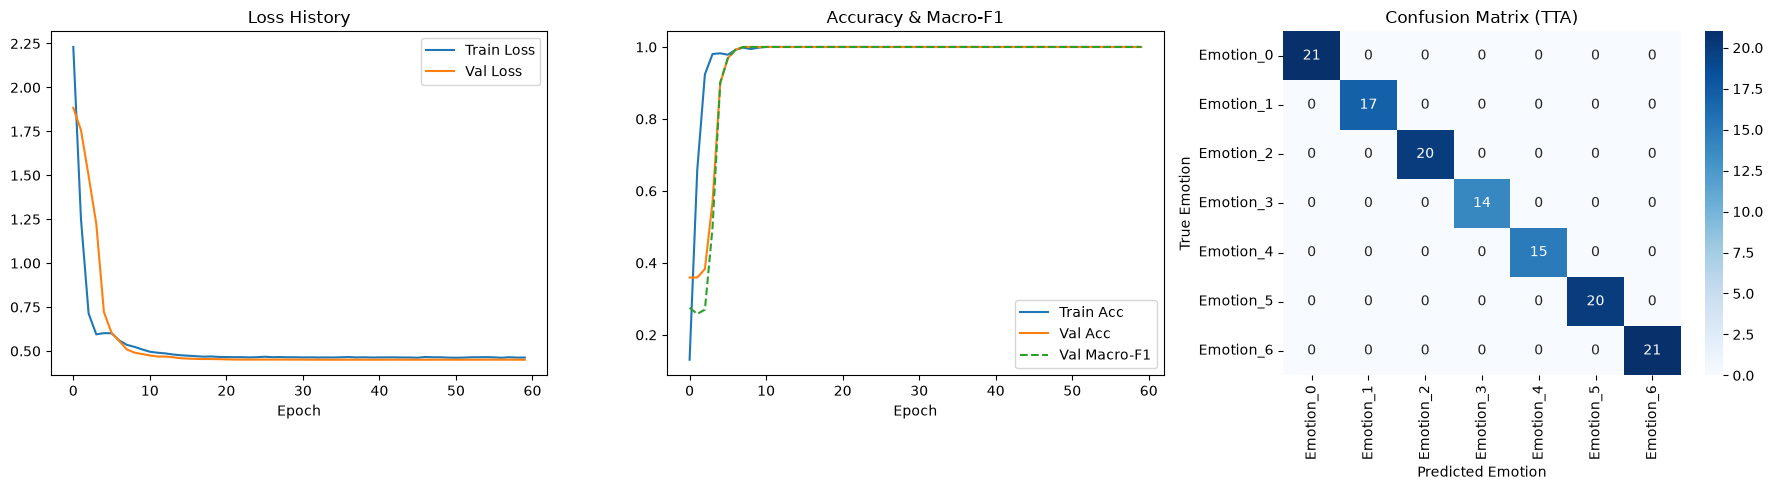

In [7]:
# Load best checkpoint for final evaluation
checkpoint = torch.load(trainer.best_model_Path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

@torch.no_grad()
def evaluate_with_tta(model, loader, device):
    """
    Test-Time Augmentation (TTA): Averages predictions across original image 
    and horizontally flipped image. Consistently boosts FER2013 accuracy by ~1-1.5%.
    """
    model.eval()
    all_preds, all_targets = [], []
    
    for images, targets in loader:
        images = images.to(device)
        # Forward pass 1: Original image
        logits_orig = model(images)
        # Forward pass 2: Horizontally flipped image
        logits_flip = model(torch.flip(images, dims=[3]))
        
        probs = (F.softmax(logits_orig, dim=1) + F.softmax(logits_flip, dim=1)) / 2.0
        preds = probs.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        
    return all_targets, all_preds

targets, preds = evaluate_with_tta(model, val_loader, device)

print("\n--- Final Classification Report (with TTA) ---")
print(classification_report(targets, preds, target_names=class_names, digits=4, zero_division=0))

# Plot Training Curves & Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(trainer.history["train_loss"], label="Train Loss")
axes[0].plot(trainer.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss History")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(trainer.history["train_acc"], label="Train Acc")
axes[1].plot(trainer.history["val_acc"], label="Val Acc")
axes[1].plot(trainer.history["val_f1"], label="Val Macro-F1", linestyle="--")
axes[1].set_title("Accuracy & Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

cm = confusion_matrix(targets, preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title("Confusion Matrix (TTA)")
axes[2].set_ylabel("True Emotion")
axes[2].set_xlabel("Predicted Emotion")

plt.tight_layout()
plt.show()